# Thesis figures

Publication-style figures for the thesis report. Each figure is drawn at its
final print width (≈ 16 cm, i.e. `\linewidth`), so font sizes in the PDF are the
sizes that appear in print: include them with `width=\linewidth` and no scaling.

Run all cells; every figure is written as `<name>.pdf` (for LaTeX) and
`<name>.png` (preview) next to this notebook.

In [13]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import colors, patches

OUT_DIR = Path.cwd()

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "Helvetica", "DejaVu Sans"],
    "font.size": 9,
    "pdf.fonttype": 42,  # embed TrueType -> selectable text in the PDF
    "ps.fonttype": 42,
})
FS_TITLE, FS_BODY, FS_SMALL = 10, 9, 8
MONO = "Liberation Mono"
INK, MUTED, RULE = "#000000", "#555555", "#181818"
BOX_FILL = "#FAFAFA"
ENRICH_C, DERIVED_C = "#1B7A3A", "#B3261E"  # payload field roles
FIG_W = 6.14  # inches = \linewidth (US letter, 3 cm margins)


def canvas(w, h):
    """Figure whose data coordinates are inches, origin bottom-left."""
    fig = plt.figure(figsize=(w, h))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, w)
    ax.set_ylim(0, h)
    ax.axis("off")
    return fig, ax


def text_width(ax, s, **kw):
    """Rendered width of a string in inches."""
    r = ax.figure.canvas.get_renderer()
    t = ax.text(0, 0, s, **kw)
    w = t.get_window_extent(renderer=r).width / ax.figure.dpi
    t.remove()
    return w


def dashed_box(ax, x, y, w, h):
    ax.add_patch(patches.FancyBboxPatch(
        (x, y), w, h, boxstyle="round,pad=0,rounding_size=0.08",
        fc=BOX_FILL, ec=RULE, lw=1.2, ls=(0, (3, 3))))


def wrap(ax, text, width, first_indent=0.0, **kw):
    """Greedy word wrap by rendered width (inches)."""
    lines, line, avail = [], "", width - first_indent
    for word in text.split():
        trial = f"{line} {word}".strip()
        if line and text_width(ax, trial, **kw) > avail:
            lines.append(line)
            line, avail = word, width
        else:
            line = trial
    return lines + [line]


def save(fig, name):
    fig.savefig(OUT_DIR / f"{name}.pdf")
    fig.savefig(OUT_DIR / f"{name}.png", dpi=300)
    frac = fig.get_figwidth() / FIG_W
    print(f"wrote {name}.pdf / {name}.png  ->  "
          f"\\includegraphics[width={frac:.2f}\\linewidth]{{figures/{name}.pdf}}")


from matplotlib.transforms import Affine2D
from matplotlib.textpath import TextPath
from matplotlib.font_manager import FontProperties


def text_as_path(ax, x, y, s, size, family=None, color=INK):
    """Draw s as vector outlines, vertically centred on y. Outlined text is not
    selectable, so PDF viewers cannot auto-link it (used for https:// URLs)."""
    tp = TextPath((0, 0), s, size=size, prop=FontProperties(family=family))
    scale = 1 / 72  # points -> inches (canvas units)
    bb = tp.get_extents()
    tf = Affine2D().scale(scale).translate(x, y - (bb.y0 + bb.height / 2) * scale)
    ax.add_patch(patches.PathPatch(tf.transform_path(tp), fc=color, ec="none", lw=0))


## Dense and sparse vector representation

Values come from the FastEmbed `Qdrant/bm25` output in
`llm4ehr/rag_evaluation/visualize.ipynb` and the `nomic-embed-text` embedding of
the same sentence.

wrote dense_sparse_vector_representation.pdf / dense_sparse_vector_representation.png  ->  \includegraphics[width=1.00\linewidth]{figures/dense_sparse_vector_representation.pdf}


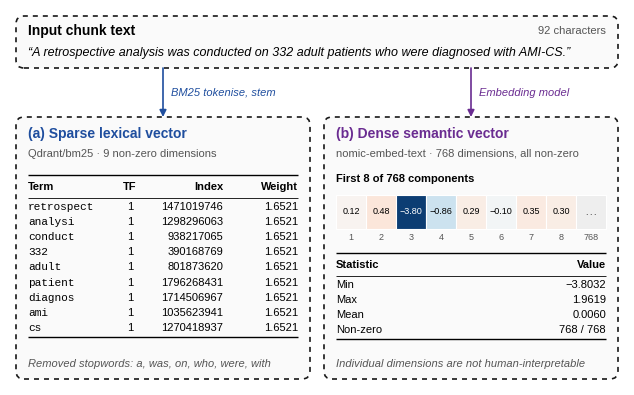

In [14]:
TEXT = ("A retrospective analysis was conducted on 332 adult patients "
        "who were diagnosed with AMI-CS.")

SPARSE = [  # (term, tf, index, weight)
    ("retrospect", 1, 1471019746, 1.6521),
    ("analysi", 1, 1298296063, 1.6521),
    ("conduct", 1, 938217065, 1.6521),
    ("332", 1, 390168769, 1.6521),
    ("adult", 1, 801873620, 1.6521),
    ("patient", 1, 1796268431, 1.6521),
    ("diagnos", 1, 1714506967, 1.6521),
    ("ami", 1, 1035623941, 1.6521),
    ("cs", 1, 1270418937, 1.6521),
]
STOPWORDS = ["a", "was", "on", "who", "were", "with"]

DENSE_DIM = 768
DENSE_HEAD = [0.1234, 0.4773, -3.8032, -0.8620, 0.2920, -0.0957, 0.3526, 0.2963]
DENSE_STATS = [("Min", "\u22123.8032"), ("Max", "1.9619"),
               ("Mean", "0.0060"), ("Non-zero", "768 / 768")]

SPARSE_C, DENSE_C = "#1F4E9E", "#6A2C91"

W, H = FIG_W, 3.75
fig, ax = canvas(W, H)


def rule(x0, x1, y, lw=0.8):
    ax.plot([x0, x1], [y, y], color=INK, lw=lw, solid_capstyle="butt")


def arrow(x, y0, y1, label, color):
    ax.annotate("", xy=(x, y1), xytext=(x, y0),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=1.2,
                                shrinkA=0, shrinkB=0, mutation_scale=10))
    ax.text(x + 0.08, (y0 + y1) / 2, label, ha="left", va="center",
            fontsize=FS_SMALL, color=color, style="italic")


# input ------------------------------------------------------------------
M = 0.06
in_h = 0.52
in_y = H - M - in_h
dashed_box(ax, M, in_y, W - 2 * M, in_h)
ax.text(M + 0.12, in_y + in_h - 0.15, "Input chunk text", fontsize=FS_TITLE,
        fontweight="bold", va="center")
ax.text(W - M - 0.12, in_y + in_h - 0.15, f"{len(TEXT)} characters",
        fontsize=FS_SMALL, color=MUTED, va="center", ha="right")
ax.text(M + 0.12, in_y + 0.15, f"\u201c{TEXT}\u201d", fontsize=FS_BODY,
        va="center", style="italic")

# panels -----------------------------------------------------------------
gap = 0.14
pw = (W - 2 * M - gap) / 2
ph = 2.62
py = M
lx, rx = M, M + pw + gap

arrow(lx + pw / 2, in_y, py + ph, "BM25 tokenise, stem", SPARSE_C)
arrow(rx + pw / 2, in_y, py + ph, "Embedding model", DENSE_C)


def panel_header(x, title, sub, color):
    dashed_box(ax, x, py, pw, ph)
    ax.text(x + 0.12, py + ph - 0.17, title, fontsize=FS_TITLE,
            fontweight="bold", color=color, va="center")
    ax.text(x + 0.12, py + ph - 0.37, sub, fontsize=FS_SMALL, color=MUTED,
            va="center")


row_h = 0.152

# (a) sparse
panel_header(lx, "(a) Sparse lexical vector",
             f"Qdrant/bm25 \u00b7 {len(SPARSE)} non-zero dimensions", SPARSE_C)
tx0, tx1 = lx + 0.12, lx + pw - 0.12
cols = [("Term", tx0, "left"), ("TF", tx0 + 1.02, "center"),
        ("Index", tx0 + 1.95, "right"), ("Weight", tx1, "right")]
y = py + ph - 0.58
rule(tx0, tx1, y, 1.0)
y -= 0.12
for name, x, ha in cols:
    ax.text(x, y, name, fontsize=FS_SMALL, fontweight="bold", ha=ha, va="center")
y -= 0.11
rule(tx0, tx1, y, 0.6)
for term, tf, idx, wt in SPARSE:
    y -= row_h
    vals = [term, str(tf), str(idx), f"{wt:.4f}"]
    for (name, x, ha), v in zip(cols, vals):
        ax.text(x, y + row_h / 2 - 0.01, v, fontsize=FS_SMALL, ha=ha,
                va="center", family=MONO if name == "Term" else None)
rule(tx0, tx1, y - 0.02, 1.0)
ax.text(tx0, py + 0.15, "Removed stopwords: " + ", ".join(STOPWORDS),
        fontsize=FS_SMALL, color=MUTED, va="center", style="italic")

# (b) dense
panel_header(rx, "(b) Dense semantic vector",
             f"nomic-embed-text \u00b7 {DENSE_DIM} dimensions, all non-zero", DENSE_C)
dx0, dx1 = rx + 0.12, rx + pw - 0.12
ax.text(dx0, py + ph - 0.62, f"First {len(DENSE_HEAD)} of {DENSE_DIM} components",
        fontsize=FS_SMALL, fontweight="bold", va="center")

norm = colors.TwoSlopeNorm(vmin=-4, vcenter=0, vmax=4)
cmap = plt.get_cmap("RdBu_r")
cw = (dx1 - dx0) / (len(DENSE_HEAD) + 1)
ch = 0.34
cy = py + ph - 1.12
for i, v in enumerate(DENSE_HEAD):
    c = cmap(norm(v))
    ax.add_patch(patches.Rectangle((dx0 + i * cw, cy), cw, ch, fc=c,
                                   ec="white", lw=0.8))
    lum = 0.299 * c[0] + 0.587 * c[1] + 0.114 * c[2]
    ax.text(dx0 + (i + 0.5) * cw, cy + ch / 2, f"{v:.2f}".replace("-", "\u2212"),
            fontsize=6.5, ha="center", va="center",
            color="white" if lum < 0.5 else INK)
    ax.text(dx0 + (i + 0.5) * cw, cy - 0.09, str(i + 1), fontsize=6.5,
            ha="center", va="center", color=MUTED)
last = len(DENSE_HEAD)
ax.add_patch(patches.Rectangle((dx0 + last * cw, cy), cw, ch, fc="#EEEEEE",
                               ec="white", lw=0.8))
ax.text(dx0 + (last + 0.5) * cw, cy + ch / 2, "\u2026", fontsize=FS_BODY,
        ha="center", va="center", color=MUTED)
ax.text(dx0 + (last + 0.5) * cw, cy - 0.09, str(DENSE_DIM), fontsize=6.5,
        ha="center", va="center", color=MUTED)

y = cy - 0.24
rule(dx0, dx1, y, 1.0)
y -= 0.12
ax.text(dx0, y, "Statistic", fontsize=FS_SMALL, fontweight="bold", va="center")
ax.text(dx1, y, "Value", fontsize=FS_SMALL, fontweight="bold", va="center", ha="right")
y -= 0.11
rule(dx0, dx1, y, 0.6)
for name, v in DENSE_STATS:
    y -= row_h
    ax.text(dx0, y + row_h / 2 - 0.01, name, fontsize=FS_SMALL, va="center")
    ax.text(dx1, y + row_h / 2 - 0.01, v, fontsize=FS_SMALL, va="center", ha="right")
rule(dx0, dx1, y - 0.02, 1.0)
ax.text(dx0, py + 0.15, "Individual dimensions are not human-interpretable",
        fontsize=FS_SMALL, color=MUTED, va="center", style="italic")

save(fig, "dense_sparse_vector_representation")


## Evaluation question categories

The 38 benchmark field IDs grouped into 7 categories. IDs match the question set
used by `llm4ehr/rag_evaluation`, except that the dataset ID `outcome.targe_disease`
is shown with its corrected spelling `outcome.target_disease`. Column widths are measured from the rendered text, so long IDs are
never clipped.

wrote evaluation_question_categories.pdf / evaluation_question_categories.png  ->  \includegraphics[width=1.00\linewidth]{figures/evaluation_question_categories.pdf}


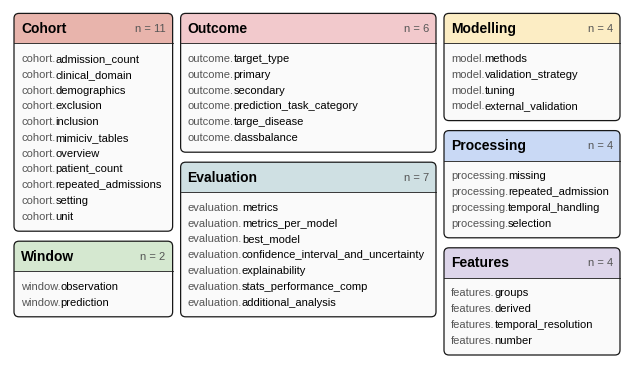

In [15]:
# (title, ID prefix, header colour, fields)
CATEGORIES = {
    "cohort": ("Cohort", "cohort", "#E8B4AC", [
        "admission_count", "clinical_domain", "demographics", "exclusion",
        "inclusion", "mimiciv_tables", "overview", "patient_count",
        "repeated_admissions", "setting", "unit"]),
    "window": ("Window", "window", "#D5E8D0", ["observation", "prediction"]),
    "outcome": ("Outcome", "outcome", "#F2C9CC", [
        "target_type", "primary", "secondary", "prediction_task_category",
        "target_disease", "classbalance"]),
    "evaluation": ("Evaluation", "evaluation", "#CFE0E3", [
        "metrics", "metrics_per_model", "best_model",
        "confidence_interval_and_uncertainty", "explainability",
        "stats_performance_comp", "additional_analysis"]),
    "modelling": ("Modelling", "model", "#FCEDC4", [
        "methods", "validation_strategy", "tuning", "external_validation"]),
    "processing": ("Processing", "processing", "#C9D9F5", [
        "missing", "repeated_admission", "temporal_handling", "selection"]),
    "features": ("Features", "features", "#DDD5EA", [
        "groups", "derived", "temporal_resolution", "number"]),
}
# columns of stacked boxes, balanced by height
COLUMNS = [["cohort", "window"], ["outcome", "evaluation"],
           ["modelling", "processing", "features"]]
assert sum(len(c[3]) for c in CATEGORIES.values()) == 38

FS_ID = 8
M, GAP_X, GAP_Y = 0.04, 0.08, 0.10
HEAD_H, ROW_H, PAD, INSET = 0.30, 0.158, 0.07, 0.07


def box_height(key):
    return HEAD_H + 2 * PAD + ROW_H * len(CATEGORIES[key][3])


H = 2 * M + max(sum(box_height(k) for k in col) + GAP_Y * (len(col) - 1)
                for col in COLUMNS)
fig, ax = canvas(FIG_W, H)

# natural column widths = widest full ID (prefix + field) + insets
natural = [max(text_width(ax, f"{CATEGORIES[k][1]}.{f}", fontsize=FS_ID)
               for k in col for f in CATEGORIES[k][3]) + 2 * INSET
           for col in COLUMNS]
usable = FIG_W - 2 * M - GAP_X * (len(COLUMNS) - 1)
assert sum(natural) <= usable, f"IDs too wide: {sum(natural):.2f} > {usable:.2f} in"
extra = (usable - sum(natural)) / len(COLUMNS)  # share leftover space evenly
col_w = [n + extra for n in natural]


def category_box(key, x, y_top, w):
    title, prefix, colour, fields = CATEGORIES[key]
    h = box_height(key)
    y = y_top - h
    rounded = dict(boxstyle="round,pad=0,rounding_size=0.05")
    ax.add_patch(patches.FancyBboxPatch((x, y), w, h, fc=BOX_FILL, ec="none", **rounded))
    # coloured header band with a square bottom edge
    ax.add_patch(patches.FancyBboxPatch((x, y_top - HEAD_H), w, HEAD_H,
                                        fc=colour, ec="none", **rounded))
    ax.add_patch(patches.Rectangle((x, y_top - HEAD_H), w, HEAD_H / 2,
                                   fc=colour, ec="none"))
    ax.plot([x, x + w], [y_top - HEAD_H] * 2, color=RULE, lw=0.6)
    ax.add_patch(patches.FancyBboxPatch((x, y), w, h, fc="none", ec=RULE,
                                        lw=0.9, **rounded))

    hy = y_top - HEAD_H / 2
    ax.text(x + INSET, hy, title, fontsize=FS_TITLE, fontweight="bold", va="center")
    ax.text(x + w - INSET, hy, f"n = {len(fields)}", fontsize=FS_SMALL,
            va="center", ha="right", color=MUTED)

    # full ID: prefix in grey, field name in black
    prefix_w = text_width(ax, f"{prefix}.", fontsize=FS_ID)
    ry = y_top - HEAD_H - PAD - ROW_H / 2
    for f in fields:
        ax.text(x + INSET, ry, f"{prefix}.", fontsize=FS_ID, va="center", color=MUTED)
        ax.text(x + INSET + prefix_w, ry, f, fontsize=FS_ID, va="center", color=INK)
        ry -= ROW_H


x = M
for col, w in zip(COLUMNS, col_w):
    y_top = H - M
    for key in col:
        category_box(key, x, y_top, w)
        y_top -= box_height(key) + GAP_Y
    x += w + GAP_X

save(fig, "evaluation_question_categories")


## Evaluation questions table

The 38 benchmark questions as a LaTeX `longtable` for the thesis appendix
(`tables/evaluation_questions.tex`, included with `\input`). The wording is read
from `llm4ehr/rag_evaluation/datasets/ML4EHR.csv`, so the table always matches the
evaluated dataset. In that CSV the `category` column holds the field ID and
`field_id` holds the category; the code below names them by content. The dataset ID
`outcome.targe_disease` is shown as `outcome.target_disease`, as in the figure above.

In [ ]:
import csv
from collections import OrderedDict

DATASET = OUT_DIR.parents[2] / "llm4ehr/rag_evaluation/datasets/ML4EHR.csv"
TABLE_OUT = (OUT_DIR.parents[2] / "THESIS_REPORT_Structured-Extraction-of-Retrospective-MIMIC-IV-Studies"
             / "tables/evaluation_questions.tex")
CATEGORY_TITLES = {  # dataset category -> heading used in the thesis
    "cohort": "Cohort", "outcome": "Outcome", "window": "Window",
    "features": "Features", "processing": "Processing",
    "modelling": "Modelling", "evaluation": "Evaluation",
}
ID_DISPLAY = {"outcome.targe_disease": "outcome.target_disease"}  # typo in the dataset ID
N_PAPERS = 12


def tex_escape(text):
    repl = {"\\": r"\textbackslash{}", "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#",
            "_": r"\_", "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}", "^": r"\^{}"}
    return "".join(repl.get(ch, ch) for ch in text)


rows = list(csv.DictReader(open(DATASET, encoding="utf-8-sig")))
questions = OrderedDict()  # field ID -> [category, question, reported count]
category = None
for r in rows:
    category = (r["field_id"] or "").strip() or category  # blank = same as above
    entry = questions.setdefault(r["category"].strip(), [category, r["question"].strip(), 0])
    entry[2] += r["status"].strip().lower() == "reported"
assert len(questions) == 38 and len(rows) == 38 * N_PAPERS

lines = [
    "% Generated by extra_materials/thesis /figures/thesis_figures.ipynb -- do not edit by hand.",
    r"{\small",
    r"\begin{longtable}{@{}>{\raggedright\arraybackslash}p{0.27\linewidth}"
    r" >{\raggedright\arraybackslash}p{0.55\linewidth} r@{}}",
    r"\caption{The 38 evaluation questions, grouped by category and identified by their"
    r" field ID. \textit{Reported} gives the number of the twelve papers that report the"
    r" requested information according to the reference dataset.}"
    r"\label{tab:evaluation-questions}\\",
    r"\toprule",
    r"\textbf{Field ID} & \textbf{Question} & \textbf{Reported} \\",
    r"\midrule",
    r"\endfirsthead",
    r"\multicolumn{3}{@{}l}{\small\textit{(continued)}}\\",
    r"\toprule",
    r"\textbf{Field ID} & \textbf{Question} & \textbf{Reported} \\",
    r"\midrule",
    r"\endhead",
    r"\bottomrule",
    r"\endlastfoot",
]
current = None
for fid, (category, question, reported) in questions.items():
    if category != current:
        if current is not None:
            lines.append(r"\addlinespace")
        lines.append(rf"\multicolumn{{3}}{{@{{}}l}}{{\textbf{{{CATEGORY_TITLES[category]}}}}} \\")
        current = category
    lines.append(rf"\path{{{ID_DISPLAY.get(fid, fid)}}} & {tex_escape(question)} & {reported}/{N_PAPERS} \\")
lines += [r"\end{longtable}", "}"]

TABLE_OUT.parent.mkdir(exist_ok=True)
TABLE_OUT.write_text("\n".join(lines) + "\n", encoding="utf-8")
print(f"wrote {TABLE_OUT.name}: {len(questions)} questions, "
      f"{sum(v[2] for v in questions.values())} reported cells")

## Section-aware chunk

`combined_text` exactly as built in `llm4ehr/app/rag/services/indexing_service.py`:
`"Title: {title}\nSection: {section}\n\nContent:\n{chunk}"`. Green labels mark
payload fields reused to enrich the chunk; red marks fields created during chunking.

wrote section_aware_chunk.pdf / section_aware_chunk.png  ->  \includegraphics[width=1.00\linewidth]{figures/section_aware_chunk.pdf}


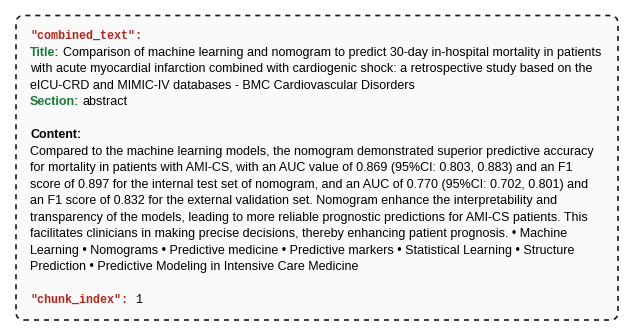

In [16]:
CHUNK_TITLE = ("Comparison of machine learning and nomogram to predict 30-day "
               "in-hospital mortality in patients with acute myocardial infarction "
               "combined with cardiogenic shock: a retrospective study based on the "
               "eICU-CRD and MIMIC-IV databases - BMC Cardiovascular Disorders")
CHUNK_SECTION = "abstract"
CHUNK_CONTENT = (
    "Compared to the machine learning models, the nomogram demonstrated superior "
    "predictive accuracy for mortality in patients with AMI-CS, with an AUC value of "
    "0.869 (95%CI: 0.803, 0.883) and an F1 score of 0.897 for the internal test set "
    "of nomogram, and an AUC of 0.770 (95%CI: 0.702, 0.801) and an F1 score of 0.832 "
    "for the external validation set. Nomogram enhance the interpretability and "
    "transparency of the models, leading to more reliable prognostic predictions for "
    "AMI-CS patients. This facilitates clinicians in making precise decisions, thereby "
    "enhancing patient prognosis. \u2022 Machine Learning \u2022 Nomograms \u2022 "
    "Predictive medicine \u2022 Predictive markers \u2022 Statistical Learning "
    "\u2022 Structure Prediction \u2022 Predictive Modeling in Intensive Care Medicine")
CHUNK_INDEX = 1

FS_KEY = 8.5
LINE_H, INSET, M = 0.165, 0.14, 0.06
W = FIG_W
fig, ax = canvas(W, 1)  # height fixed after wrapping
inner = W - 2 * M - 2 * INSET
body = dict(fontsize=FS_BODY)
label = dict(fontsize=FS_BODY, fontweight="bold")
key = dict(fontsize=FS_KEY, family=MONO, fontweight="bold")

title_lbl_w = text_width(ax, "Title: ", **label)
title_lines = wrap(ax, CHUNK_TITLE, inner, first_indent=title_lbl_w, **body)
content_lines = wrap(ax, CHUNK_CONTENT, inner, **body)

# rows: (x offset, label, label colour, text)
rows = [(0, '"combined_text":', DERIVED_C, None, key)]
rows += [(0, "Title:", ENRICH_C, title_lines[0], label)]
rows += [(0, None, None, t, None) for t in title_lines[1:]]
rows += [(0, "Section:", ENRICH_C, CHUNK_SECTION, label), None,
         (0, "Content:", INK, None, label)]
rows += [(0, None, None, t, None) for t in content_lines]
rows += [None, (0, '"chunk_index":', DERIVED_C, str(CHUNK_INDEX), key)]

H = 2 * M + 2 * 0.12 + LINE_H * len(rows)
fig.set_size_inches(W, H)
ax.set_ylim(0, H)
dashed_box(ax, M, M, W - 2 * M, H - 2 * M)

x0 = M + INSET
y = H - M - 0.12 - LINE_H / 2
for row in rows:
    if row is not None:
        _, lbl, colour, txt, style = row
        x = x0
        if lbl:
            ax.text(x, y, lbl, color=colour, va="center", **style)
            x += text_width(ax, lbl + " ", **style)
        if txt:
            ax.text(x, y, txt, va="center", color=INK,
                    **(dict(fontsize=FS_KEY, family=MONO) if style is key else body))
    y -= LINE_H

save(fig, "section_aware_chunk")


## Qdrant point payload

Payload stored with every indexed chunk (long values truncated with \u2026). The
dense and sparse vectors are stored beside the payload as named vectors.

wrote qdrant_payload.pdf / qdrant_payload.png  ->  \includegraphics[width=0.90\linewidth]{figures/qdrant_payload.pdf}


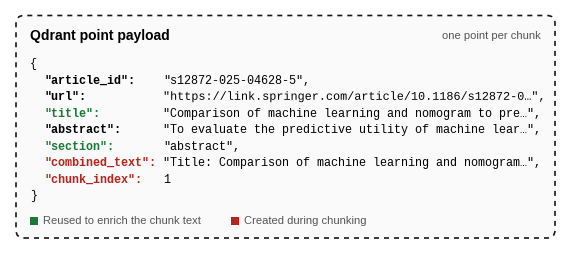

In [17]:
PAYLOAD = [  # (key, JSON value, role)
    ("article_id", '"s12872-025-04628-5"', None),
    ("url", '"https://link.springer.com/article/10.1186/s12872-0\u2026"', None),
    ("title", '"Comparison of machine learning and nomogram to pre\u2026"', "enrich"),
    ("abstract", '"To evaluate the predictive utility of machine lear\u2026"', None),
    ("section", '"abstract"', "enrich"),
    ("combined_text", '"Title: Comparison of machine learning and nomogram\u2026"', "derived"),
    ("chunk_index", "1", "derived"),
]
ROLE_C = {None: INK, "enrich": ENRICH_C, "derived": DERIVED_C}
LEGEND = [(ENRICH_C, "Reused to enrich the chunk text"),
          (DERIVED_C, "Created during chunking")]

FS_CODE = 8.5
LINE_H, INSET, M = 0.165, 0.14, 0.06
code_kw = dict(fontsize=FS_CODE, family=MONO)
fig, ax = canvas(FIG_W, 1)

key_w = max(text_width(ax, f'"{k}": ', **code_kw) for k, _, _ in PAYLOAD)
indent = text_width(ax, "  ", **code_kw)
line_w = max(indent + key_w + text_width(ax, v + ",", **code_kw) for _, v, _ in PAYLOAD)
W = min(FIG_W, line_w + 2 * (M + INSET))

n_lines = len(PAYLOAD) + 2  # braces
H = 2 * M + 0.40 + LINE_H * n_lines + 0.34
fig.set_size_inches(W, H)
ax.set_xlim(0, W)
ax.set_ylim(0, H)
dashed_box(ax, M, M, W - 2 * M, H - 2 * M)

x0 = M + INSET
y = H - M - 0.20
ax.text(x0, y, "Qdrant point payload", fontsize=FS_TITLE, fontweight="bold", va="center")
ax.text(W - M - INSET, y, "one point per chunk", fontsize=FS_SMALL, color=MUTED,
        va="center", ha="right")
y -= 0.20 + LINE_H / 2
ax.text(x0, y, "{", va="center", **code_kw)
for i, (k, v, role) in enumerate(PAYLOAD):
    y -= LINE_H
    sep = "," if i < len(PAYLOAD) - 1 else ""
    ax.text(x0 + indent, y, f'"{k}":', color=ROLE_C[role], va="center",
            fontweight="bold", **code_kw)
    if k == "url":  # outlined so viewers don't turn the https:// text into a link
        text_as_path(ax, x0 + indent + key_w, y, v + sep, FS_CODE, MONO)
    else:
        ax.text(x0 + indent + key_w, y, v + sep, va="center", **code_kw)
y -= LINE_H
ax.text(x0, y, "}", va="center", **code_kw)

# legend
lx, ly = x0, M + 0.17
for colour, text in LEGEND:
    ax.add_patch(patches.Rectangle((lx, ly - 0.04), 0.08, 0.08, fc=colour, ec="none"))
    ax.text(lx + 0.13, ly, text, fontsize=FS_SMALL, va="center", color=MUTED)
    lx += 0.13 + text_width(ax, text, fontsize=FS_SMALL) + 0.3

save(fig, "qdrant_payload")


## Retrieval scope prompts

Prompt text is loaded from `llm4ehr/app/rag/prompts/system_prompt.py`, so the figure
always matches the code. As in `llm4ehr/app/rag/pipeline.py`, each scope uses exactly
one system prompt, followed by the retrieved context.

wrote retrieval_scope_prompts.pdf / retrieval_scope_prompts.png  ->  \includegraphics[width=1.00\linewidth]{figures/retrieval_scope_prompts.pdf}


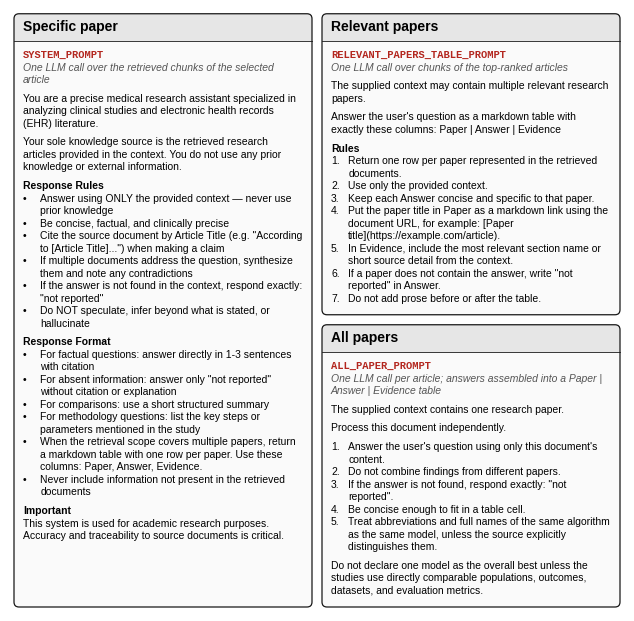

In [18]:
import importlib.util
import re

_spec = importlib.util.spec_from_file_location(
    "system_prompt", OUT_DIR.parents[2] / "llm4ehr/app/rag/prompts/system_prompt.py")
prompts = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(prompts)

SCOPES = [  # (scope, prompt constant, how the pipeline calls the LLM)
    ("Specific paper", "SYSTEM_PROMPT",
     "One LLM call over the retrieved chunks of the selected article"),
    ("Relevant papers", "RELEVANT_PAPERS_TABLE_PROMPT",
     "One LLM call over chunks of the top-ranked articles"),
    ("All papers", "ALL_PAPER_PROMPT",
     "One LLM call per article; answers assembled into a Paper | Answer | Evidence table"),
]

FS_P = 7.5
P_LINE = 0.125
P_INSET, P_HEAD = 0.09, 0.27
M, GAP = 0.04, 0.10
col_w = (FIG_W - 2 * M - GAP) / 2
fig, ax = canvas(FIG_W, 1)

body = dict(fontsize=FS_P)
bold = dict(fontsize=FS_P, fontweight="bold")


def layout_prompt(text, width):
    """Turn prompt markdown into draw ops: (dx, text, style); None = half-line gap."""
    # merge continuation lines (indented, or plain text following plain text)
    blocks = []
    for raw in text.strip().splitlines():
        line = raw.rstrip()
        if not line:
            blocks.append(None)
        elif blocks and blocks[-1] and (raw.startswith("   ") or (
                not re.match(r"^(- |\d+\. |## )", line)
                and not blocks[-1].startswith("## ")
                and not (blocks[-1].endswith(":") and len(blocks[-1]) < 30))):
            blocks[-1] += " " + line.strip()
        else:
            blocks.append(line.strip())
    ops = []
    for b in blocks:
        if b is None:
            if ops and ops[-1] is not None:
                ops.append(None)
            continue
        if b.startswith("## ") or (b.endswith(":") and len(b) < 30):
            ops.append((0, b.lstrip("# ").rstrip(":"), bold))
            continue
        m = re.match(r"^(- |\d+\. )(.*)$", b)
        if m:
            marker = "\u2022" if m.group(1) == "- " else m.group(1).strip()
            hang = text_width(ax, "00. ", **body)
            lines = wrap(ax, m.group(2), width - hang, **body)
            ops.append((0, marker, body))
            ops[-1] = [(0, marker, body), (hang, lines[0], body)]
            ops.extend((hang, l, body) for l in lines[1:])
            continue
        ops.extend((0, l, body) for l in wrap(ax, b, width, **body))
    while ops and ops[-1] is None:
        ops.pop()
    return ops


def ops_height(ops):
    return sum(P_LINE / 2 if o is None else P_LINE for o in ops)


boxes = []
for scope, const, call in SCOPES:
    inner = col_w - 2 * P_INSET
    note = wrap(ax, call, inner, fontsize=FS_SMALL - 0.5)
    ops = layout_prompt(getattr(prompts, const), inner)
    h = P_HEAD + 0.08 + (len(note) + 1) * P_LINE + 0.06 + ops_height(ops) + 0.10
    boxes.append([scope, const, note, ops, h])

# left column: specific paper; right column: relevant + all, bottoms aligned
left, r1, r2 = boxes
H_in = max(left[4], r1[4] + GAP + r2[4])
left[4] = H_in
r2[4] = H_in - GAP - r1[4]
H = H_in + 2 * M
fig.set_size_inches(FIG_W, H)
ax.set_ylim(0, H)


def draw_prompt_box(x, y_top, w, box):
    scope, const, note, ops, h = box
    rounded = dict(boxstyle="round,pad=0,rounding_size=0.05")
    ax.add_patch(patches.FancyBboxPatch((x, y_top - h), w, h, fc=BOX_FILL,
                                        ec="none", **rounded))
    ax.add_patch(patches.FancyBboxPatch((x, y_top - P_HEAD), w, P_HEAD,
                                        fc="#E6E6E6", ec="none", **rounded))
    ax.add_patch(patches.Rectangle((x, y_top - P_HEAD), w, P_HEAD / 2,
                                   fc="#E6E6E6", ec="none"))
    ax.plot([x, x + w], [y_top - P_HEAD] * 2, color=RULE, lw=0.6)
    ax.add_patch(patches.FancyBboxPatch((x, y_top - h), w, h, fc="none", ec=RULE,
                                        lw=0.9, **rounded))
    hy = y_top - P_HEAD / 2
    ax.text(x + P_INSET, hy, scope, fontsize=FS_TITLE, fontweight="bold", va="center")

    y = y_top - P_HEAD - 0.08 - P_LINE / 2
    ax.text(x + P_INSET, y, const, fontsize=FS_SMALL - 0.5, family=MONO,
            fontweight="bold", color=DERIVED_C, va="center")
    y -= P_LINE
    for l in note:
        ax.text(x + P_INSET, y, l, fontsize=FS_SMALL - 0.5, style="italic",
                color=MUTED, va="center")
        y -= P_LINE
    y -= 0.06
    for op in ops:
        if op is None:
            y -= P_LINE / 2
            continue
        for dx, t, style in (op if isinstance(op, list) else [op]):
            if "://" in t:  # outlined so viewers don't turn the URL into a link
                text_as_path(ax, x + P_INSET + dx, y, t, style["fontsize"])
            else:
                ax.text(x + P_INSET + dx, y, t, va="center", color=INK, **style)
        y -= P_LINE


draw_prompt_box(M, H - M, col_w, left)
draw_prompt_box(M + col_w + GAP, H - M, col_w, r1)
draw_prompt_box(M + col_w + GAP, H - M - r1[4] - GAP, col_w, r2)

save(fig, "retrieval_scope_prompts")


## RAGAS metrics

Pairwise relations scored by the five RAGAS metrics used in
`llm4ehr/rag_evaluation/evaluate_rag.py` (`Faithfulness`, `AnswerRelevancy`,
`AnswerCorrectness`, `ContextRecall`, `LLMContextPrecisionWithReference`).

wrote RAGA_metrices.pdf / RAGA_metrices.png  ->  \includegraphics[width=0.80\linewidth]{figures/RAGA_metrices.pdf}


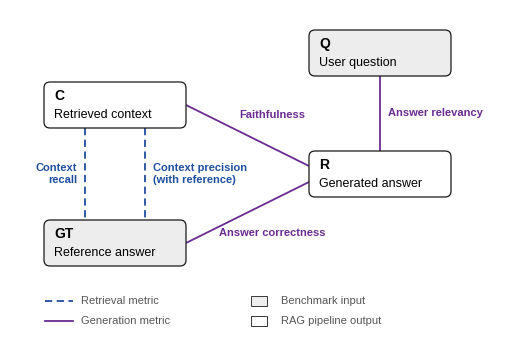

In [19]:
RETR_C, GEN_C = SPARSE_C, DENSE_C
BENCH_FILL, PIPE_FILL = "#EDEDED", "#FFFFFF"

W, H = 4.9, 3.25
fig, ax = canvas(W, H)
NW, NH = 1.42, 0.46

NODES = {  # key: (centre x, centre y, label, description, source); labels = notation of the metric definitions
    "C": (1.05, 2.30, "$C$", "Retrieved context", "pipeline"),
    "GT": (1.05, 0.92, "$g$", "Reference answer", "benchmark"),
    "R": (3.70, 1.61, "$r$", "Generated answer", "pipeline"),
    "Q": (3.70, 2.82, "$q$", "User question", "benchmark"),
}


def node(key):
    cx, cy, lab, desc, src = NODES[key]
    ax.add_patch(patches.FancyBboxPatch(
        (cx - NW / 2, cy - NH / 2), NW, NH, boxstyle="round,pad=0,rounding_size=0.06",
        fc=BENCH_FILL if src == "benchmark" else PIPE_FILL, ec=RULE, lw=0.9, zorder=3))
    ax.text(cx - NW / 2 + 0.10, cy + 0.09, lab, fontsize=FS_TITLE, fontweight="bold",
            va="center", zorder=4)
    ax.text(cx - NW / 2 + 0.10, cy - 0.10, desc, fontsize=FS_BODY, va="center", zorder=4)


def edge(p0, p1, colour, dashed, label, lpos, ha="center"):
    ax.plot([p0[0], p1[0]], [p0[1], p1[1]], color=colour, lw=1.3,
            ls=(0, (4, 2.5)) if dashed else "-", zorder=1, solid_capstyle="butt")
    ax.text(*lpos, label, fontsize=FS_SMALL, color=colour, fontweight="bold",
            ha=ha, va="center")


cx, cy = NODES["C"][:2]
gx, gy = NODES["GT"][:2]
rx, ry = NODES["R"][:2]
qx, qy = NODES["Q"][:2]

# retrieval metrics: context vs reference (two parallel links)
edge((cx - 0.30, cy - NH / 2), (gx - 0.30, gy + NH / 2), RETR_C, True,
     "Context\nrecall", (cx - 0.38, (cy + gy) / 2), ha="right")
edge((cx + 0.30, cy - NH / 2), (gx + 0.30, gy + NH / 2), RETR_C, True,
     "Context precision\n(with reference)", (cx + 0.38, (cy + gy) / 2), ha="left")
# generation metrics
edge((qx, qy - NH / 2), (rx, ry + NH / 2), GEN_C, False,
     "Answer relevancy", (qx + 0.08, (qy + ry) / 2), ha="left")
edge((cx + NW / 2, cy), (rx - NW / 2, ry + 0.08), GEN_C, False,
     "Faithfulness", ((cx + rx) / 2 + 0.25, (cy + ry) / 2 + 0.25))
edge((gx + NW / 2, gy), (rx - NW / 2, ry - 0.08), GEN_C, False,
     "Answer correctness", ((gx + rx) / 2 + 0.25, (gy + ry) / 2 - 0.25))

for k in NODES:
    node(k)

# legend: 2 x 2 grid
items = [("line", RETR_C, True, "Retrieval metric"),
         ("box", BENCH_FILL, None, "Benchmark input"),
         ("line", GEN_C, False, "Generation metric"),
         ("box", PIPE_FILL, None, "RAG pipeline output")]
for i, (kind, c, dashed, text) in enumerate(items):
    lx, ly = 0.35 + (i % 2) * 2.0, 0.34 - (i // 2) * 0.20
    if kind == "line":
        ax.plot([lx, lx + 0.28], [ly, ly], color=c, lw=1.3,
                ls=(0, (4, 2.5)) if dashed else "-")
    else:
        ax.add_patch(patches.Rectangle((lx + 0.06, ly - 0.05), 0.16, 0.10, fc=c,
                                       ec=RULE, lw=0.6))
    ax.text(lx + 0.36, ly, text, fontsize=FS_SMALL, va="center", color=MUTED)

save(fig, "RAGA_metrices")


## Sequence diagram helper

Minimal UML sequence-diagram renderer shared by the workflow figures, drawn at
print width (PlantUML layouts with 8 lifelines shrink to ≈4 pt text once scaled to
`\linewidth`). Lifeline x positions are set by hand per diagram; message labels
wrap to at least `MIN_LABEL_W` and stay inside the innermost frame.

Events: `("section", title)`, `("msg"|"ret", src, dst, text)`, `("self", who, text)`,
`("note", who, text, x_right[, advance])`, `("loop"|"alt", condition, x0, x1)`,
`("else", condition)`, `("end",)`.

In [20]:
FS_MSG, FS_HDR = 8, 8.5
SEQ_LH = 0.13       # text line height
MIN_LABEL_W = 2.3   # labels may run over lifelines (white background)
HDR_H, HDR_TOP = 0.42, 0.05
LIFE_C = "#8A8A8A"


def sequence_diagram(participants, events, autonumber=False, w=FIG_W,
                     min_label_w=MIN_LABEL_W):
    """participants: [(key, label, kind, x)] with kind in {"actor", "box", "db"}."""
    X = {k: x for k, _, _, x in participants}
    fig, ax = canvas(w, 1)
    msg_kw = dict(fontsize=FS_MSG)
    num_kw = dict(fontsize=FS_MSG, fontweight="bold")
    label_bg = dict(fc="white", ec="none", pad=0.6)

    def header(label, kind, x, y_top):
        hw = max(text_width(ax, l, fontsize=FS_HDR) for l in label.split("\n")) + 0.14
        y = y_top - HDR_H
        if kind == "actor":  # stick figure above the name
            hx, hy = x, y_top - 0.035
            ax.add_patch(patches.Circle((hx, hy), 0.03, fc="white", ec=RULE, lw=0.8))
            ax.plot([hx, hx], [hy - 0.03, hy - 0.12], color=RULE, lw=0.8)
            ax.plot([hx - 0.06, hx + 0.06], [hy - 0.06, hy - 0.06], color=RULE, lw=0.8)
            ax.plot([hx - 0.05, hx, hx + 0.05], [hy - 0.19, hy - 0.12, hy - 0.19],
                    color=RULE, lw=0.8)
            ax.text(x, y + 0.07, label, fontsize=FS_HDR, ha="center", va="center")
            return
        if kind == "db":  # cylinder
            e, fc = 0.07, "#EDEDED"
            ax.add_patch(patches.Rectangle((x - hw / 2, y + e / 2), hw, HDR_H - e,
                                           fc=fc, ec="none"))
            ax.add_patch(patches.Ellipse((x, y + e / 2), hw, e, fc=fc, ec=RULE, lw=0.8))
            ax.add_patch(patches.Ellipse((x, y_top - e / 2), hw, e, fc=fc, ec=RULE, lw=0.8))
            for xs in (x - hw / 2, x + hw / 2):
                ax.plot([xs, xs], [y + e / 2, y_top - e / 2], color=RULE, lw=0.8)
            ax.add_patch(patches.Rectangle((x - hw / 2 + 0.01, y + e / 2), hw - 0.02,
                                           0.012, fc=fc, ec="none", zorder=3))
            ax.text(x, y + HDR_H / 2 + 0.005, label, fontsize=FS_HDR, ha="center",
                    va="center", linespacing=1.0)
            return
        ax.add_patch(patches.FancyBboxPatch((x - hw / 2, y), hw, HDR_H,
                                            boxstyle="round,pad=0,rounding_size=0.04",
                                            fc=BOX_FILL, ec=RULE, lw=0.8))
        ax.text(x, y + HDR_H / 2, label, fontsize=FS_HDR, ha="center", va="center",
                linespacing=1.1)

    def arrow(x0, x1, y, dashed):
        ax.annotate("", xy=(x1, y), xytext=(x0, y), zorder=3,
                    arrowprops=dict(arrowstyle="->" if dashed else "-|>", lw=0.9,
                                    color=INK, ls=(0, (3, 2)) if dashed else "-",
                                    shrinkA=0, shrinkB=0, mutation_scale=8))

    def label_line(x, y, num, text, ha):
        """One label line; an optional bold step number precedes the text."""
        nw = text_width(ax, num, **num_kw) if num else 0.0
        tw = text_width(ax, text, **msg_kw)
        x0 = {"center": x - (nw + tw) / 2, "left": x}[ha]
        if num:
            ax.text(x0, y, num, ha="left", va="center", zorder=4, bbox=label_bg, **num_kw)
        ax.text(x0 + nw, y, text, ha="left", va="center", zorder=4, bbox=label_bg, **msg_kw)

    def frame_tag(kind, cond, x0, y):
        tag_w = text_width(ax, kind, **num_kw) + 0.14
        ax.add_patch(patches.Polygon(
            [(x0, y), (x0 + tag_w, y), (x0 + tag_w, y - 0.12),
             (x0 + tag_w - 0.06, y - 0.18), (x0, y - 0.18)],
            closed=True, fc="#F2F2F2", ec=RULE, lw=0.8, zorder=3))
        ax.text(x0 + 0.06, y - 0.09, kind, va="center", zorder=4, **num_kw)
        ax.text(x0 + tag_w + 0.08, y - 0.09, f"[{cond}]", va="center", zorder=4, **num_kw)

    y = -HDR_TOP
    header_y = y
    y -= HDR_H + 0.12
    frames, step = [], 0
    for ev in events:
        kind = ev[0]
        if kind in ("msg", "ret", "self"):
            step += 1
        num = f"{step}. " if autonumber and kind in ("msg", "ret", "self") else ""
        if kind == "section":
            y -= 0.05
            for dy in (0.018, -0.018):
                ax.plot([0.02, w - 0.02], [y + dy] * 2, color=RULE, lw=0.6, zorder=2)
            ax.text(w / 2, y, ev[1], fontsize=FS_HDR, fontweight="bold", ha="center",
                    va="center", zorder=4, bbox=dict(fc="#F2F2F2", ec=RULE, lw=0.6, pad=2.5))
            y -= 0.19
        elif kind in ("msg", "ret"):
            _, a, b, text = ev
            x0, x1 = X[a], X[b]
            lo, hi = (frames[-1][2] + 0.05, frames[-1][3] - 0.05) if frames else (0.02, w - 0.02)
            avail = min(max(abs(x1 - x0) - 0.12, min_label_w), hi - lo - 0.06)
            nw = text_width(ax, num, **num_kw) if num else 0.0
            lines = wrap(ax, text, avail, first_indent=nw, **msg_kw)
            widths = [text_width(ax, l, **msg_kw) for l in lines]
            half = max(widths[0] + nw, *widths) / 2 + 0.03
            cx = min(max((x0 + x1) / 2, lo + half), hi - half)
            for i, l in enumerate(lines):
                label_line(cx, y - (i + 0.5) * SEQ_LH, num if i == 0 else "", l, "center")
            y -= len(lines) * SEQ_LH + 0.035
            arrow(x0, x1, y, dashed=kind == "ret")
            y -= 0.075
        elif kind == "self":
            _, a, text = ev
            x0 = X[a]
            y -= 0.03
            ax.plot([x0, x0 + 0.20, x0 + 0.20], [y, y, y - 0.09], color=INK, lw=0.9, zorder=3)
            arrow(x0 + 0.20, x0, y - 0.09, dashed=False)
            hi = frames[-1][3] - 0.05 if frames else w - 0.02
            nw = text_width(ax, num, **num_kw) if num else 0.0
            lines = wrap(ax, text, hi - x0 - 0.33, first_indent=nw, **msg_kw)
            for i, l in enumerate(lines):
                label_line(x0 + 0.27 + (nw if i else 0), y - 0.045 - i * SEQ_LH,
                           num if i == 0 else "", l, "left")
            y -= 0.09 + (len(lines) - 1) * SEQ_LH + 0.10
        elif kind == "note":
            _, a, text, x_right, *flow = ev  # flow=[False]: draw beside next rows
            nx = X[a] + 0.10
            lines = [l for para in text.split("\n")
                     for l in wrap(ax, para, x_right - nx - 0.12, **msg_kw)]
            h = len(lines) * SEQ_LH + 0.08
            ax.add_patch(patches.Rectangle((nx, y - h), x_right - nx, h, fc=BOX_FILL,
                                           ec="#888888", lw=0.7, zorder=3))
            for i, l in enumerate(lines):
                ax.text(nx + 0.06, y - 0.04 - (i + 0.5) * SEQ_LH, l, ha="left",
                        va="center", zorder=4, **msg_kw)
            if not flow or flow[0]:
                y -= h + 0.08
        elif kind in ("loop", "alt"):
            _, cond, fx0, fx1 = ev
            frames.append((kind, cond, fx0, fx1, y))
            frame_tag(kind, cond, fx0, y)
            y -= 0.24
        elif kind == "else":
            fx0, fx1 = frames[-1][2], frames[-1][3]
            y -= 0.02
            ax.plot([fx0, fx1], [y, y], color=RULE, lw=0.7, ls=(0, (3, 2)), zorder=2)
            ax.text(fx0 + 0.06, y - 0.09, f"[{ev[1]}]", va="center", zorder=4, **num_kw)
            y -= 0.24
        elif kind == "end":
            _, cond, fx0, fx1, fy = frames.pop()
            y -= 0.02
            ax.add_patch(patches.Rectangle((fx0, y), fx1 - fx0, fy - y, fc="none",
                                           ec=RULE, lw=0.8, zorder=2))
            y -= 0.12

    y_end = y - 0.02
    for key, label, kind, x in participants:
        header(label, kind, x, header_y)
        ax.plot([x, x], [header_y - HDR_H, y_end], color=LIFE_C, lw=0.7,
                ls=(0, (4, 3)), zorder=0)

    h = -y_end + 0.04
    fig.set_size_inches(w, h)
    ax.set_ylim(-h, 0)
    return fig


## RAG evaluation and scoring workflow

wrote rag_evaluation_scoring.pdf / rag_evaluation_scoring.png  ->  \includegraphics[width=1.00\linewidth]{figures/rag_evaluation_scoring.pdf}


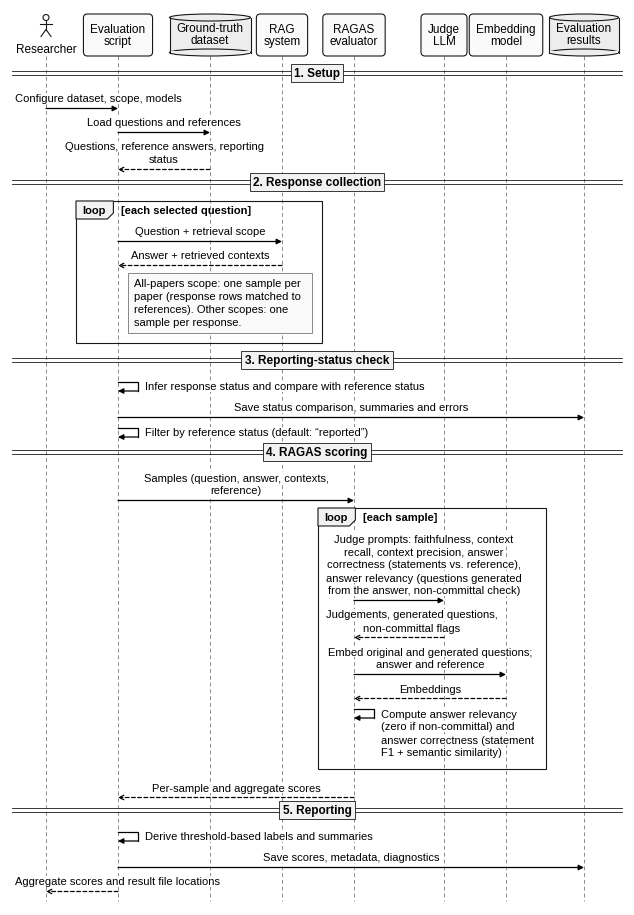

In [21]:
PARTICIPANTS = [  # (key, label, kind, centre x in inches)
    ("res", "Researcher", "actor", 0.36),
    ("script", "Evaluation\nscript", "box", 1.08),
    ("data", "Ground-truth\ndataset", "db", 2.00),
    ("rag", "RAG\nsystem", "box", 2.72),
    ("ragas", "RAGAS\nevaluator", "box", 3.44),
    ("judge", "Judge\nLLM", "box", 4.34),
    ("emb", "Embedding\nmodel", "box", 4.96),
    ("out", "Evaluation\nresults", "db", 5.74),
]
X = {k: x for k, _, _, x in PARTICIPANTS}

EVENTS = [
    ("section", "1. Setup"),
    ("msg", "res", "script", "Configure dataset, scope, models"),
    ("msg", "script", "data", "Load questions and references"),
    ("ret", "data", "script", "Questions, reference answers, reporting status"),
    ("section", "2. Response collection"),
    ("loop", "each selected question", X["script"] - 0.42, X["rag"] + 0.40),
    ("msg", "script", "rag", "Question + retrieval scope"),
    ("ret", "rag", "script", "Answer + retrieved contexts"),
    ("note", "script", "All-papers scope: one sample per paper (response rows "
     "matched to references). Other scopes: one sample per response.", X["rag"] + 0.30),
    ("end",),
    ("section", "3. Reporting-status check"),
    ("self", "script", "Infer response status and compare with reference status"),
    ("msg", "script", "out", "Save status comparison, summaries and errors"),
    ("self", "script", "Filter by reference status (default: \u201creported\u201d)"),
    ("section", "4. RAGAS scoring"),
    ("msg", "script", "ragas", "Samples (question, answer, contexts, reference)"),
    ("loop", "each sample", X["ragas"] - 0.36, X["emb"] + 0.40),
    ("msg", "ragas", "judge", "Judge prompts: faithfulness, context recall, context "
     "precision, answer correctness (statements vs. reference), answer relevancy "
     "(questions generated from the answer, non-committal check)"),
    ("ret", "judge", "ragas", "Judgements, generated questions, non-committal flags"),
    ("msg", "ragas", "emb", "Embed original and generated questions; answer and reference"),
    ("ret", "emb", "ragas", "Embeddings"),
    ("self", "ragas", "Compute answer relevancy (zero if non-committal) and answer "
     "correctness (statement F1 + semantic similarity)"),
    ("end",),
    ("ret", "ragas", "script", "Per-sample and aggregate scores"),
    ("section", "5. Reporting"),
    ("self", "script", "Derive threshold-based labels and summaries"),
    ("msg", "script", "out", "Save scores, metadata, diagnostics"),
    ("ret", "script", "res", "Aggregate scores and result file locations"),
]

save(sequence_diagram(PARTICIPANTS, EVENTS), "rag_evaluation_scoring")


## Retrieval pipeline

Query processing, scope-dependent retrieval and answer generation (step numbers as
in the thesis text).

wrote retrieval_pipeline.pdf / retrieval_pipeline.png  ->  \includegraphics[width=1.00\linewidth]{figures/retrieval_pipeline.pdf}


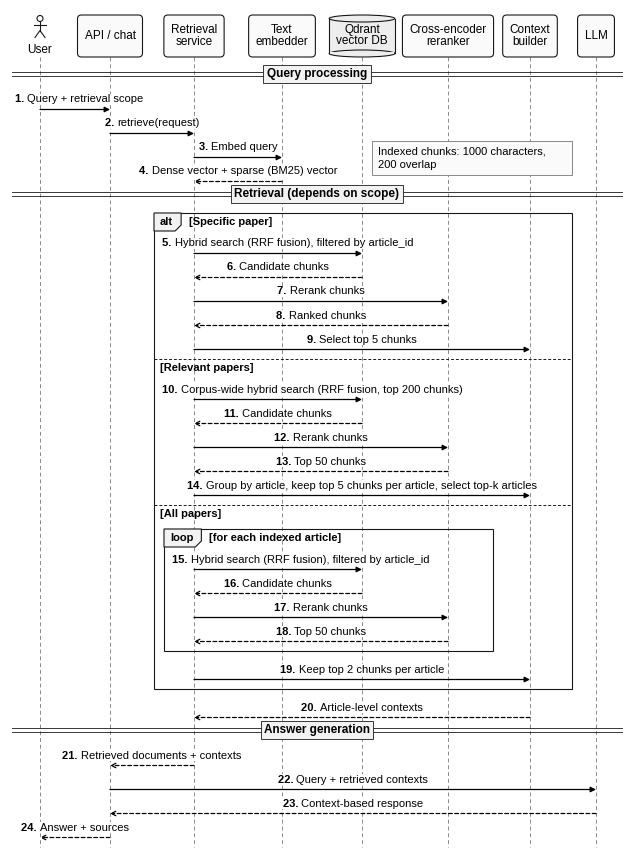

In [22]:
PARTICIPANTS = [  # (key, label, kind, centre x in inches)
    ("user", "User", "actor", 0.30),
    ("api", "API / chat", "box", 1.00),
    ("rs", "Retrieval\nservice", "box", 1.84),
    ("emb", "Text\nembedder", "box", 2.72),
    ("qd", "Qdrant\nvector DB", "db", 3.52),
    ("rr", "Cross-encoder\nreranker", "box", 4.38),
    ("cb", "Context\nbuilder", "box", 5.20),
    ("llm", "LLM", "box", 5.86),
]
X = {k: x for k, _, _, x in PARTICIPANTS}
ALT_X = (X["rs"] - 0.40, X["cb"] + 0.42)

EVENTS = [
    ("section", "Query processing"),
    ("msg", "user", "api", "Query + retrieval scope"),
    ("msg", "api", "rs", "retrieve(request)"),
    ("note", "qd", "Indexed chunks: 1000 characters, 200 overlap", X["cb"] + 0.42,
     False),
    ("msg", "rs", "emb", "Embed query"),
    ("ret", "emb", "rs", "Dense vector + sparse (BM25) vector"),
    ("section", "Retrieval (depends on scope)"),
    ("alt", "Specific paper", *ALT_X),
    ("msg", "rs", "qd", "Hybrid search (RRF fusion), filtered by article_id"),
    ("ret", "qd", "rs", "Candidate chunks"),
    ("msg", "rs", "rr", "Rerank chunks"),
    ("ret", "rr", "rs", "Ranked chunks"),
    ("msg", "rs", "cb", "Select top 5 chunks"),
    ("else", "Relevant papers"),
    ("msg", "rs", "qd", "Corpus-wide hybrid search (RRF fusion, top 200 chunks)"),
    ("ret", "qd", "rs", "Candidate chunks"),
    ("msg", "rs", "rr", "Rerank chunks"),
    ("ret", "rr", "rs", "Top 50 chunks"),
    ("msg", "rs", "cb", "Group by article, keep top 5 chunks per article, "
     "select top-k articles"),
    ("else", "All papers"),
    ("loop", "for each indexed article", X["rs"] - 0.30, X["rr"] + 0.45),
    ("msg", "rs", "qd", "Hybrid search (RRF fusion), filtered by article_id"),
    ("ret", "qd", "rs", "Candidate chunks"),
    ("msg", "rs", "rr", "Rerank chunks"),
    ("ret", "rr", "rs", "Top 50 chunks"),
    ("end",),
    ("msg", "rs", "cb", "Keep top 2 chunks per article"),
    ("end",),
    ("ret", "cb", "rs", "Article-level contexts"),
    ("section", "Answer generation"),
    ("ret", "rs", "api", "Retrieved documents + contexts"),
    ("msg", "api", "llm", "Query + retrieved contexts"),
    ("ret", "llm", "api", "Context-based response"),
    ("ret", "api", "user", "Answer + sources"),
]

save(sequence_diagram(PARTICIPANTS, EVENTS, autonumber=True,
                      min_label_w=4.0), "retrieval_pipeline")


## Literature discovery and article extraction

wrote Literature_discovery_and_extraction.pdf / Literature_discovery_and_extraction.png  ->  \includegraphics[width=1.00\linewidth]{figures/Literature_discovery_and_extraction.pdf}


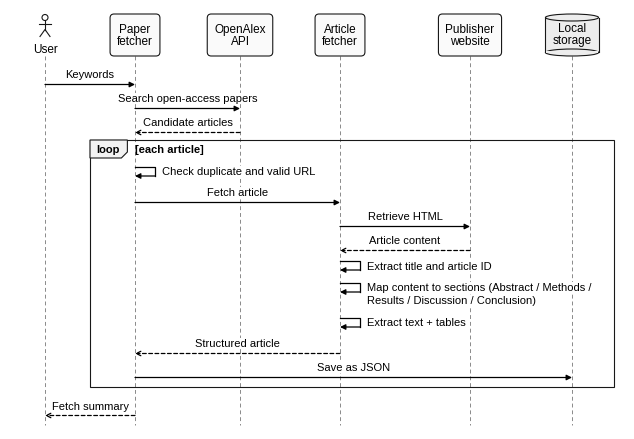

In [23]:
PARTICIPANTS = [  # (key, label, kind, centre x in inches)
    ("user", "User", "actor", 0.35),
    ("pf", "Paper\nfetcher", "box", 1.25),
    ("oa", "OpenAlex\nAPI", "box", 2.30),
    ("af", "Article\nfetcher", "box", 3.30),
    ("pub", "Publisher\nwebsite", "box", 4.60),
    ("store", "Local\nstorage", "db", 5.62),
]
X = {k: x for k, _, _, x in PARTICIPANTS}

EVENTS = [
    ("msg", "user", "pf", "Keywords"),
    ("msg", "pf", "oa", "Search open-access papers"),
    ("ret", "oa", "pf", "Candidate articles"),
    ("loop", "each article", X["pf"] - 0.45, X["store"] + 0.42),
    ("self", "pf", "Check duplicate and valid URL"),
    ("msg", "pf", "af", "Fetch article"),
    ("msg", "af", "pub", "Retrieve HTML"),
    ("ret", "pub", "af", "Article content"),
    ("self", "af", "Extract title and article ID"),
    ("self", "af", "Map content to sections (Abstract / Methods / Results / "
     "Discussion / Conclusion)"),
    ("self", "af", "Extract text + tables"),
    ("ret", "af", "pf", "Structured article"),
    ("msg", "pf", "store", "Save as JSON"),
    ("end",),
    ("ret", "pf", "user", "Fetch summary"),
]

save(sequence_diagram(PARTICIPANTS, EVENTS), "Literature_discovery_and_extraction")


## RAG system overview

wrote RAG_overview.pdf / RAG_overview.png  ->  \includegraphics[width=1.00\linewidth]{figures/RAG_overview.pdf}


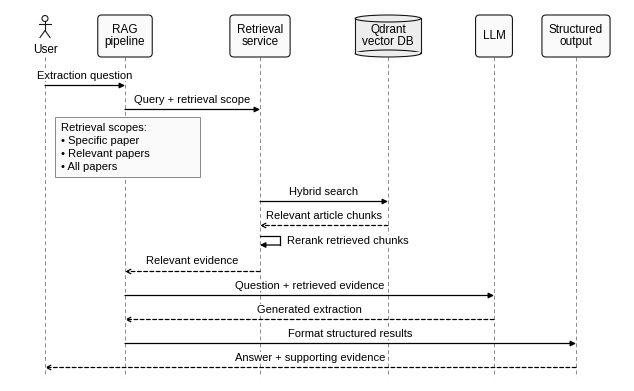

In [24]:
PARTICIPANTS = [  # (key, label, kind, centre x in inches)
    ("user", "User", "actor", 0.35),
    ("pipe", "RAG\npipeline", "box", 1.15),
    ("rs", "Retrieval\nservice", "box", 2.50),
    ("qd", "Qdrant\nvector DB", "db", 3.78),
    ("llm", "LLM", "box", 4.84),
    ("out", "Structured\noutput", "box", 5.66),
]
X = {k: x for k, _, _, x in PARTICIPANTS}

EVENTS = [
    ("msg", "user", "pipe", "Extraction question"),
    ("msg", "pipe", "rs", "Query + retrieval scope"),
    ("note", "user", "Retrieval scopes:\n\u2022 Specific paper\n\u2022 Relevant papers\n"
     "\u2022 All papers", X["pipe"] + 0.75),
    ("msg", "rs", "qd", "Hybrid search"),
    ("ret", "qd", "rs", "Relevant article chunks"),
    ("self", "rs", "Rerank retrieved chunks"),
    ("ret", "rs", "pipe", "Relevant evidence"),
    ("msg", "pipe", "llm", "Question + retrieved evidence"),
    ("ret", "llm", "pipe", "Generated extraction"),
    ("msg", "pipe", "out", "Format structured results"),
    ("ret", "out", "user", "Answer + supporting evidence"),
]

save(sequence_diagram(PARTICIPANTS, EVENTS), "RAG_overview")
